# Simulate and filter

## Setup

Load the baseline config and build the interaction network.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config, model

cfg = config.load_config(ROOT / "configs" / "degroot_base.yaml")
params = cfg.model
W_graph, W = model.build_network(cfg.network, np.random.default_rng(cfg.seed))
n = cfg.network.n_agents

print(f"n = {n}, λ = {params.self_weight}")
print(f"σ_p = {params.process_noise_sd}, σ_e = {params.expression_noise_sd}, "
      f"σ_m = {params.measurement_noise_sd}")

n = 50, λ = 0.3
σ_p = 0.05, σ_e = 0.1, σ_m = 0.2


Helper for the sanity checks below: simulate hidden opinions $x$ and expressions $s$ for $T$ steps from a given $x_0$. All checks share the same $x_0 \sim \mathcal U(0,1)$.

In [2]:
def run(params, W, x0, T, rng):
    """Simulate (x, s), each of shape (T, n), starting from x0."""
    x = np.empty((T, x0.size))
    s = np.empty((T, x0.size))
    x[0] = x0
    s[0] = model.express(x0, params, rng)
    for t in range(1, T):
        x[t] = model.step(x[t - 1], s[t - 1], W, params, rng)
        s[t] = model.express(x[t], params, rng)
    return x, s


x0 = np.random.default_rng(123).uniform(0, 1, n)

## Check 1 — Classical limit

With $\sigma_p = \sigma_e = 0$ we have $s = x$, so the update is classical DeGroot,
$x_t = A x_{t-1}$ with $A = \lambda I + (1-\lambda) W$. $A$ is row-stochastic and, on a connected
non-bipartite graph with $\lambda > 0$, primitive, so all opinions converge to the consensus
$\pi^\top x_0$, where $\pi$ is the left eigenvector of $A$ for eigenvalue 1, normalised to sum 1.
After 500 steps every agent should be within $10^{-6}$ of that value.

π·x0 = 0.484760
max_i |x_i,T − π·x0| = 8.20e-08


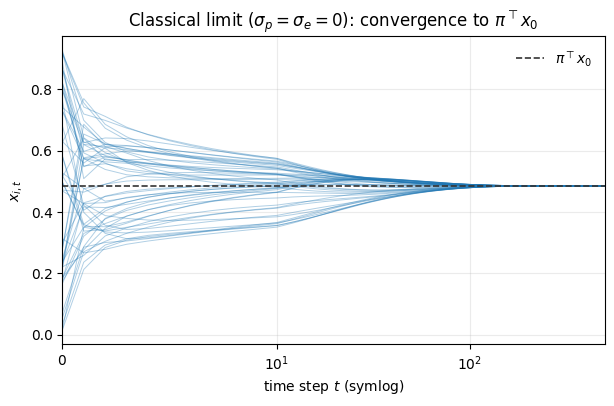

In [3]:
params0 = replace(params, process_noise_sd=0.0, expression_noise_sd=0.0)
T1 = 500
x1, _ = run(params0, W, x0, T1, np.random.default_rng(0))

lam = params.self_weight
A = lam * np.eye(n) + (1 - lam) * W
vals, vecs = np.linalg.eig(A.T)
pi = np.real(vecs[:, np.argmin(np.abs(vals - 1))])
pi /= pi.sum()
consensus = pi @ x0
err = np.max(np.abs(x1[-1] - consensus))

print(f"π·x0 = {consensus:.6f}")
print(f"max_i |x_i,T − π·x0| = {err:.2e}")
assert err < 1e-6

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x1, color="C0", lw=0.7, alpha=0.35)
ax.axhline(consensus, color="0.2", ls="--", lw=1.2, label=r"$\pi^\top x_0$")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, T1)
ax.set_xlabel(r"time step $t$ (symlog)")
ax.set_ylabel(r"$x_{i,t}$")
ax.set_title(r"Classical limit ($\sigma_p = \sigma_e = 0$): convergence to $\pi^\top x_0$")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

## Check 2 — Noise behaviour

With noise, opinions no longer reach exact consensus: they fluctuate around a drifting
near-consensus. The spread across agents, $\mathrm{std}_i(x_{i,t})$, should settle at a level
that grows with each noise source. We vary $\sigma_p$ with $\sigma_e = 0$, and $\sigma_e$ with
$\sigma_p = 0$, using the same random stream for every setting. With both at zero the spread
decays geometrically (a straight line on the log axis), at a rate set by the second-largest
eigenvalue of $A$.

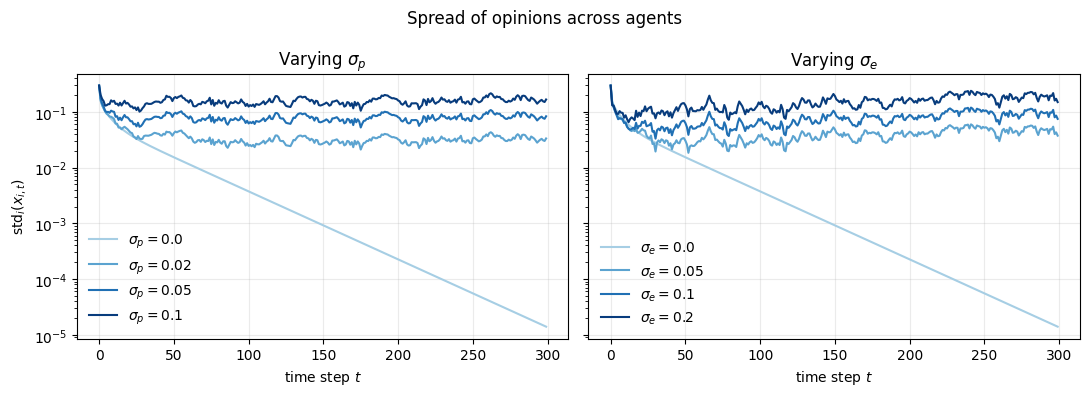

process_noise_sd = 0.0    mean std (last 100 steps) = 7.655e-05
process_noise_sd = 0.02   mean std (last 100 steps) = 3.205e-02
process_noise_sd = 0.05   mean std (last 100 steps) = 8.010e-02
process_noise_sd = 0.1    mean std (last 100 steps) = 1.602e-01
expression_noise_sd = 0.0    mean std (last 100 steps) = 7.655e-05
expression_noise_sd = 0.05   mean std (last 100 steps) = 4.680e-02
expression_noise_sd = 0.1    mean std (last 100 steps) = 9.355e-02
expression_noise_sd = 0.2    mean std (last 100 steps) = 1.870e-01


In [4]:
T2 = 300
sigma_grid = {
    "process_noise_sd": [0.0, 0.02, 0.05, 0.1],
    "expression_noise_sd": [0.0, 0.05, 0.1, 0.2],
}
symbol = {"process_noise_sd": r"\sigma_p", "expression_noise_sd": r"\sigma_e"}

spread = {}
for field, levels in sigma_grid.items():
    for level in levels:
        p = replace(params, **{"process_noise_sd": 0.0, "expression_noise_sd": 0.0, field: level})
        x, _ = run(p, W, x0, T2, np.random.default_rng(0))
        spread[field, level] = x.std(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (field, levels) in zip(axes, sigma_grid.items()):
    colors = plt.cm.Blues(np.linspace(0.35, 0.95, len(levels)))
    for color, level in zip(colors, levels):
        ax.plot(spread[field, level], color=color, lw=1.5, label=rf"${symbol[field]} = {level}$")
    ax.set_yscale("log")
    ax.set_xlabel(r"time step $t$")
    ax.set_title(rf"Varying ${symbol[field]}$")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
axes[0].set_ylabel(r"$\mathrm{std}_i(x_{i,t})$")
fig.suptitle("Spread of opinions across agents")
fig.tight_layout()
plt.show()

for field, levels in sigma_grid.items():
    means = [spread[field, level][-100:].mean() for level in levels]
    for level, m in zip(levels, means):
        print(f"{field} = {level:<5}  mean std (last 100 steps) = {m:.3e}")
    assert np.all(np.diff(means) > 0), f"spread does not increase with {field}"

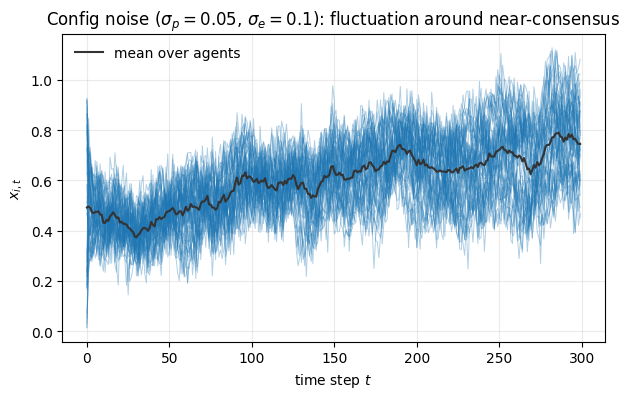

In [5]:
x_cfg, _ = run(params, W, x0, T2, np.random.default_rng(0))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_cfg, color="C0", lw=0.7, alpha=0.35)
ax.plot(x_cfg.mean(axis=1), color="0.2", lw=1.5, label=r"mean over agents")
ax.set_xlabel(r"time step $t$")
ax.set_ylabel(r"$x_{i,t}$")
ax.set_title(rf"Config noise ($\sigma_p = {params.process_noise_sd}$, "
             rf"$\sigma_e = {params.expression_noise_sd}$): fluctuation around near-consensus")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

## Check 3 — Reproducibility

All randomness flows through the `rng` passed in. Two runs with the same seed must give
bit-identical trajectories; a different seed must give different ones.

In [6]:
xa, sa = run(params, W, x0, T2, np.random.default_rng(0))
xb, sb = run(params, W, x0, T2, np.random.default_rng(0))
xc, sc = run(params, W, x0, T2, np.random.default_rng(1))

same = np.array_equal(xa, xb) and np.array_equal(sa, sb)
diff = not (np.array_equal(xa, xc) or np.array_equal(sa, sc))
print(f"seed 0 vs seed 0: {'identical' if same else 'different'}")
print(f"seed 0 vs seed 1: {'identical' if not diff else 'different'}")
assert same
assert diff

seed 0 vs seed 0: identical
seed 0 vs seed 1: different
